In [2]:
import pandas as pd
import numpy as np

# Load processed data
df_raw = pd.read_parquet('../data/processed/master_gold_contracts_12m.parquet')
df_raw['Date'] = pd.to_datetime(df_raw['Date'], format='mixed')
df_raw['Expiry Date'] = pd.to_datetime(df_raw['Expiry Date'], format='mixed')

print("Data loaded successfully!")
print("Date Range:", df_raw['Date'].min(), "to", df_raw['Date'].max())
print("Unique Symbols:", df_raw['Symbol'].unique())

Data loaded successfully!
Date Range: 2025-09-24 00:00:00 to 2026-09-23 00:00:00
Unique Symbols: ['GOLDGUINEA' 'GOLDM' 'GOLDPETAL' 'GOLDTEN']


In [3]:
# Contract Multipliers for MCX Gold Contracts
CONTRACT_MULTIPLIERS = {
    'GOLDM': 10,       # 100g contract, quoted per 10g
    'GOLDTEN': 1,      # 10g contract, quoted per 10g
    'GOLDGUINEA': 1,   # 8g contract, quoted per 8g
    'GOLDPETAL': 1     # 1g contract, quoted per 1g
}

def generate_continuous_series(df: pd.DataFrame, symbol: str) -> pd.DataFrame:
    """Selects the active contract on each day based on maximum Open Interest."""
    symbol_df = df[df['Symbol'].str.strip() == symbol].copy()
    
    # Active contract selection rule based on Open Interest
    active_idx = symbol_df.groupby('Date')['Open Interest(Lots)'].idxmax()
    continuous_df = symbol_df.loc[active_idx].sort_values('Date').reset_index(drop=True)
    
    continuous_df['Daily_Return'] = continuous_df['Close'].pct_change()
    return continuous_df

def run_ema_backtest(df: pd.DataFrame, symbol: str, fast_window=10, slow_window=30) -> pd.DataFrame:
    """Executes EMA Crossover backtest on continuous contract series."""
    df = df.copy()
    
    # Indicators
    df['EMA_Fast'] = df['Close'].ewm(span=fast_window, adjust=False).mean()
    df['EMA_Slow'] = df['Close'].ewm(span=slow_window, adjust=False).mean()
    
    # Signal Generation (+1 Long, -1 Short)
    df['Signal'] = np.where(df['EMA_Fast'] > df['EMA_Slow'], 1, -1)
    
    # Position shifted by 1 day to prevent lookahead bias
    df['Position'] = df['Signal'].shift(1)
    
    # Returns & PnL
    df['Strategy_Return'] = df['Position'] * df['Daily_Return']
    df['Cumulative_Market_Return'] = (1 + df['Daily_Return']).cumprod() - 1
    df['Cumulative_Strategy_Return'] = (1 + df['Strategy_Return']).cumprod() - 1
    
    # Absolute PnL calculation using MCX Lot Multiplier
    multiplier = CONTRACT_MULTIPLIERS.get(symbol, 1)
    df['Price_Change'] = df['Close'].diff()
    df['Strategy_PnL_Rupees'] = df['Position'] * df['Price_Change'] * multiplier
    df['Cumulative_PnL_Rupees'] = df['Strategy_PnL_Rupees'].cumsum()
    
    return df

# 1. Generate continuous series & run EMA backtest for GOLDM
goldm_cont = generate_continuous_series(df_raw, 'GOLDM')
results_df = run_ema_backtest(goldm_cont, 'GOLDM', fast_window=10, slow_window=30)

# 2. Calculate Risk-Adjusted Metrics
daily_returns = results_df['Strategy_Return'].dropna()

annualized_return = daily_returns.mean() * 252
annualized_volatility = daily_returns.std() * np.sqrt(252)
sharpe_ratio = annualized_return / annualized_volatility if annualized_volatility != 0 else 0

cum_returns = (1 + daily_returns).cumprod()
peak = cum_returns.cummax()
drawdown = (cum_returns - peak) / peak
max_drawdown = drawdown.min()

# 3. Print Results
print("--- Strategy Performance Summary: GOLDM ---")
print(f"Total Market Return:           {results_df['Cumulative_Market_Return'].iloc[-1]:.2%}")
print(f"Total Strategy Return:         {results_df['Cumulative_Strategy_Return'].iloc[-1]:.2%}")
print(f"Total Net PnL (per 1 lot):     ₹{results_df['Cumulative_PnL_Rupees'].iloc[-1]:,.2f}")
print("\n--- Risk Metrics ---")
print(f"Annualized Volatility:         {annualized_volatility:.2%}")
print(f"Sharpe Ratio:                 {sharpe_ratio:.2f}")
print(f"Max Drawdown:                 {max_drawdown:.2%}")

--- Strategy Performance Summary: GOLDM ---
Total Market Return:           33.71%
Total Strategy Return:         33.16%
Total Net PnL (per 1 lot):     ₹376,780.00

--- Risk Metrics ---
Annualized Volatility:         54.90%
Sharpe Ratio:                 2.66
Max Drawdown:                 -13.86%


In [4]:
# Multi-Contract Comparative Backtest Engine
contracts = ['GOLDM', 'GOLDTEN', 'GOLDGUINEA', 'GOLDPETAL']
comparison_data = []

for symbol in contracts:
    # 1. Continuous series construction
    cont_df = generate_continuous_series(df_raw, symbol)
    
    # 2. Run EMA (10/30) Strategy
    results = run_ema_backtest(cont_df, symbol, fast_window=10, slow_window=30)
    
    # 3. Calculate Risk Metrics
    daily_rets = results['Strategy_Return'].dropna()
    ann_ret = daily_rets.mean() * 252
    ann_vol = daily_rets.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol if ann_vol != 0 else 0
    
    cum_rets = (1 + daily_rets).cumprod()
    max_dd = ((cum_rets - cum_rets.cummax()) / cum_rets.cummax()).min()
    
    comparison_data.append({
        'Symbol': symbol,
        'Market Return': f"{results['Cumulative_Market_Return'].iloc[-1]:.2%}",
        'Strategy Return': f"{results['Cumulative_Strategy_Return'].iloc[-1]:.2%}",
        'Net PnL (₹)': f"₹{results['Cumulative_PnL_Rupees'].iloc[-1]:,.2f}",
        'Ann. Volatility': f"{ann_vol:.2%}",
        'Sharpe Ratio': f"{sharpe:.2f}",
        'Max Drawdown': f"{max_dd:.2%}"
    })

# Format into DataFrame for clear side-by-side display
summary_df = pd.DataFrame(comparison_data)
summary_df

,Symbol,Market Return,Strategy Return,Net PnL (₹),Ann. Volatility,Sharpe Ratio,Max Drawdown
0,GOLDM,33.71%,33.16%,"₹376,780.00",54.90%,2.66,-13.86%
1,GOLDTEN,34.71%,34.27%,"₹39,027.00",54.55%,2.75,-14.35%
2,GOLDGUINEA,34.49%,18.44%,"₹16,909.00",55.98%,1.66,-21.04%
3,GOLDPETAL,33.38%,17.28%,"₹1,964.00",56.47%,1.57,-21.12%


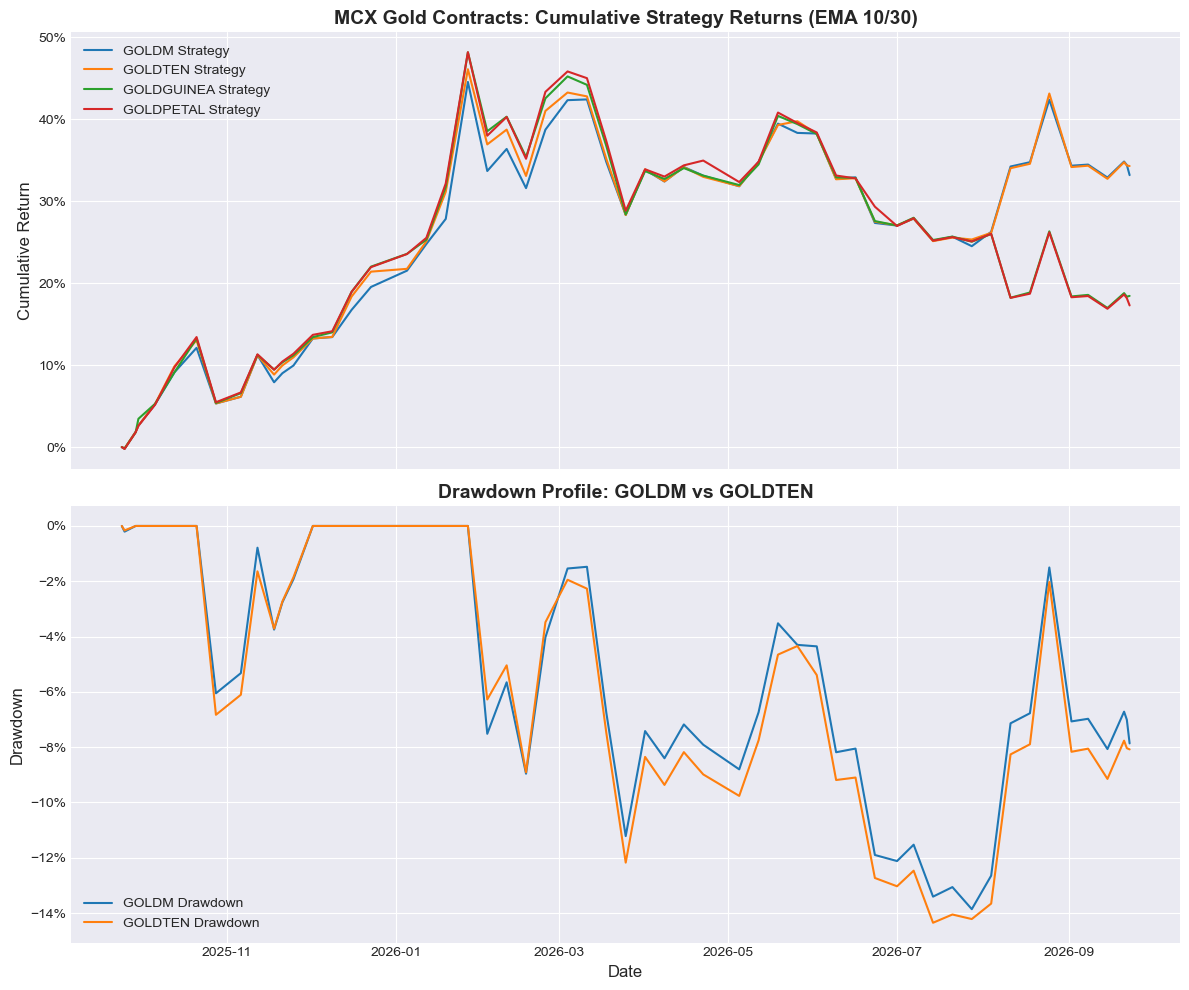

In [5]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# 1. Cumulative Returns Plot
for symbol in contracts:
    cont_df = generate_continuous_series(df_raw, symbol)
    res_df = run_ema_backtest(cont_df, symbol)
    
    daily_rets = res_df['Strategy_Return'].fillna(0)
    cum_strategy = (1 + daily_rets).cumprod() - 1
    
    axes[0].plot(res_df['Date'], cum_strategy, label=f"{symbol} Strategy")

axes[0].set_title("MCX Gold Contracts: Cumulative Strategy Returns (EMA 10/30)", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Cumulative Return", fontsize=12)
axes[0].legend(loc='upper left')
axes[0].yaxis.set_major_formatter('{x:.0%}')

# 2. Drawdown Plot for GOLDM vs GOLDTEN
for symbol in ['GOLDM', 'GOLDTEN']:
    cont_df = generate_continuous_series(df_raw, symbol)
    res_df = run_ema_backtest(cont_df, symbol)
    
    daily_rets = res_df['Strategy_Return'].fillna(0)
    cum_rets = (1 + daily_rets).cumprod()
    peak = cum_rets.cummax()
    drawdown = (cum_rets - peak) / peak
    
    axes[1].plot(res_df['Date'], drawdown, label=f"{symbol} Drawdown")

axes[1].set_title("Drawdown Profile: GOLDM vs GOLDTEN", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Date", fontsize=12)
axes[1].set_ylabel("Drawdown", fontsize=12)
axes[1].legend(loc='lower left')
axes[1].yaxis.set_major_formatter('{x:.0%}')

plt.tight_layout()
plt.show()